# Problem 14: 3D Ray Tracing & Bounding Volume Hierarchies

One self-contained notebook. Run top to bottom (**Run All**).

| Section | Content |
|---|---|
| 1 | Shared building blocks: vectors, Möller–Trumbore ray–triangle test, slab ray–box test, brute force, test scene, camera |
| 2 | **Stage 4 (V4):** median-split BVH |
| 3 | **Stage 5 (V5):** binned SAH BVH + front-to-back ordered traversal |
| 4 | Correctness check, operation counts, scaling, Q4 check, render |

## 1. Shared building blocks
### Imports, tolerance, counters, vector helpers

In [1]:
import math
import random

EPS = 1e-9


# ----------------------------------------------------------------------------
# Counters
# ----------------------------------------------------------------------------
def new_stats():
    """Counter dict passed into closest-hit functions to count work done."""
    return {"box_tests": 0, "tri_tests": 0}


# ----------------------------------------------------------------------------
# Small vector helpers (plain Python floats are faster than NumPy for 3-vectors)
# ----------------------------------------------------------------------------
def sub(a, b):
    return (a[0] - b[0], a[1] - b[1], a[2] - b[2])


def cross(a, b):
    return (a[1] * b[2] - a[2] * b[1],
            a[2] * b[0] - a[0] * b[2],
            a[0] * b[1] - a[1] * b[0])


def dot(a, b):
    return a[0] * b[0] + a[1] * b[1] + a[2] * b[2]


def normalize(a):
    n = math.sqrt(dot(a, a))
    return (a[0] / n, a[1] / n, a[2] / n)

### Ray–triangle intersection (Möller–Trumbore, Stage 2)
Solves o + t·d = v₀ + u·e₁ + v·e₂ with Cramer's rule. Returns t, or None on a miss.

In [2]:
def ray_triangle(o, d, v0, v1, v2):
    """
    Solve  o + t*d = v0 + u*e1 + v*e2  for (t, u, v) with Cramer's rule.
    Returns the hit distance t (> 0) or None if the ray misses.
    """
    e1 = sub(v1, v0)
    e2 = sub(v2, v0)
    P = cross(d, e2)
    det = dot(P, e1)
    if -EPS < det < EPS:          # ray parallel to triangle plane (or degenerate triangle)
        return None
    inv = 1.0 / det
    T = sub(o, v0)
    u = dot(P, T) * inv
    if u < 0.0 or u > 1.0:
        return None
    Q = cross(T, e1)
    v = dot(Q, d) * inv
    if v < 0.0 or u + v > 1.0:
        return None
    t = dot(Q, e2) * inv
    return t if t > EPS else None

### Ray–box intersection (Kay–Kajiya slab test, Stage 3)
The ray is inside the box only where the x, y and z slab intervals overlap. Returns (t_enter, t_exit), or None.

In [3]:
def ray_aabb(o, d, bmin, bmax):
    """
    Intersect the ray with the 3 slabs [xmin,xmax], [ymin,ymax], [zmin,zmax].
    The ray is inside the box only where all three t-intervals overlap.
    Returns (t_enter, t_exit) or None if the ray misses.
    """
    t_enter, t_exit = 0.0, math.inf
    for a in range(3):
        if abs(d[a]) < EPS:                       # ray parallel to this slab
            if o[a] < bmin[a] or o[a] > bmax[a]:
                return None
            continue
        inv = 1.0 / d[a]
        t0 = (bmin[a] - o[a]) * inv
        t1 = (bmax[a] - o[a]) * inv
        if t0 > t1:
            t0, t1 = t1, t0
        if t0 > t_enter:
            t_enter = t0
        if t1 < t_exit:
            t_exit = t1
        if t_enter > t_exit:
            return None
    return (t_enter, t_exit)

### Reference answer: brute force (tests every triangle, Θ(N) per ray)

In [4]:
def brute_force_closest_hit(o, d, vertices, faces, stats=None):
    """Returns (triangle_id, t) of the nearest hit, or (None, inf)."""
    best_id, best_t = None, math.inf
    for i, (a, b, c) in enumerate(faces):
        if stats is not None:
            stats["tri_tests"] += 1
        t = ray_triangle(o, d, vertices[a], vertices[b], vertices[c])
        if t is not None and t < best_t:
            best_id, best_t = i, t
    return best_id, best_t

### Test scene and camera
A large sphere, a 2-triangle floor and a cluster of small detailed spheres (1,922 triangles): the big-next-to-tiny mix where SAH beats median splits.

In [5]:
def _icosphere(center, radius, subdivisions):
    """Unit icosahedron refined `subdivisions` times, scaled and moved to center."""
    t = (1.0 + math.sqrt(5.0)) / 2.0
    verts = [(-1, t, 0), (1, t, 0), (-1, -t, 0), (1, -t, 0),
             (0, -1, t), (0, 1, t), (0, -1, -t), (0, 1, -t),
             (t, 0, -1), (t, 0, 1), (-t, 0, -1), (-t, 0, 1)]
    verts = [normalize(v) for v in verts]
    faces = [(0, 11, 5), (0, 5, 1), (0, 1, 7), (0, 7, 10), (0, 10, 11),
             (1, 5, 9), (5, 11, 4), (11, 10, 2), (10, 7, 6), (7, 1, 8),
             (3, 9, 4), (3, 4, 2), (3, 2, 6), (3, 6, 8), (3, 8, 9),
             (4, 9, 5), (2, 4, 11), (6, 2, 10), (8, 6, 7), (9, 8, 1)]
    for _ in range(subdivisions):
        cache, new_faces = {}, []

        def mid(i, j):
            key = (min(i, j), max(i, j))
            if key not in cache:
                a, b = verts[i], verts[j]
                verts.append(normalize(((a[0] + b[0]) / 2, (a[1] + b[1]) / 2, (a[2] + b[2]) / 2)))
                cache[key] = len(verts) - 1
            return cache[key]

        for a, b, c in faces:
            ab, bc, ca = mid(a, b), mid(b, c), mid(c, a)
            new_faces += [(a, ab, ca), (b, bc, ab), (c, ca, bc), (ab, bc, ca)]
        faces = new_faces
    verts = [(center[0] + radius * v[0], center[1] + radius * v[1], center[2] + radius * v[2])
             for v in verts]
    return verts, faces


def _append(vertices, faces, new_v, new_f):
    off = len(vertices)
    vertices.extend(new_v)
    faces.extend((a + off, b + off, c + off) for a, b, c in new_f)


def make_scene(big_sphere_detail=3, small_sphere_detail=1, n_small=8, seed=0):
    """
    Shared test scene (the one suggested in the handout):
      * one large icosphere
      * a ground plane made of 2 big triangles
      * a tight cluster of small detailed spheres (lots of tiny triangles)
    This mix of big and tiny triangles is exactly where SAH beats median splits.

    Triangle counts:  big_sphere_detail=3 -> 1280 tris, small_sphere_detail=1 -> 80 tris each.
    Returns (vertices, faces).
    """
    rng = random.Random(seed)
    vertices, faces = [], []
    v, f = _icosphere((0.0, 1.0, 0.0), 1.0, big_sphere_detail)
    _append(vertices, faces, v, f)
    # ground plane y = 0
    _append(vertices, faces,
            [(-6, 0, -6), (6, 0, -6), (6, 0, 6), (-6, 0, 6)],
            [(0, 2, 1), (0, 3, 2)])
    # cluster of small spheres
    for _ in range(n_small):
        c = (2.2 + rng.uniform(-0.5, 0.5), 0.25 + rng.uniform(0, 0.4), 0.5 + rng.uniform(-0.5, 0.5))
        v, f = _icosphere(c, 0.15, small_sphere_detail)
        _append(vertices, faces, v, f)
    return vertices, faces


def random_soup(n, seed=0, size=0.3, spread=10.0):
    """n random small triangles in a cube (for N-scaling benchmarks)."""
    rng = random.Random(seed)
    vertices, faces = [], []
    for i in range(n):
        c = (rng.uniform(0, spread), rng.uniform(0, spread), rng.uniform(0, spread))
        for _ in range(3):
            vertices.append((c[0] + rng.uniform(-size, size),
                             c[1] + rng.uniform(-size, size),
                             c[2] + rng.uniform(-size, size)))
        faces.append((3 * i, 3 * i + 1, 3 * i + 2))
    return vertices, faces


# ----------------------------------------------------------------------------
# Camera
# ----------------------------------------------------------------------------
def camera_rays(width, height, eye=(0.8, 1.6, 5.5), look_at=(0.8, 0.7, 0.0), fov_deg=50.0):
    """
    Yields (px, py, origin, direction) for every pixel of a width x height image.
    Simple pinhole camera.
    """
    fwd = normalize(sub(look_at, eye))
    right = normalize(cross(fwd, (0.0, 1.0, 0.0)))
    up = cross(right, fwd)
    scale = math.tan(math.radians(fov_deg) / 2.0)
    aspect = width / height
    for py in range(height):
        for px in range(width):
            x = (2 * (px + 0.5) / width - 1) * scale * aspect
            y = (1 - 2 * (py + 0.5) / height) * scale
            d = normalize((fwd[0] + x * right[0] + y * up[0],
                           fwd[1] + x * right[1] + y * up[1],
                           fwd[2] + x * right[2] + y * up[2]))
            yield px, py, eye, d


def triangle_normal(vertices, face):
    a, b, c = (vertices[i] for i in face)
    return normalize(cross(sub(b, a), sub(c, a)))

## 2. Stage 4 (V4): median-split BVH
### Data structure: tree nodes and helpers

In [6]:
# ----------------------------------------------------------------------------
# Data structure
# ----------------------------------------------------------------------------
class BVHNode:
    """One node of the BVH binary tree.
       Internal node: left and right children, tris is None.
       Leaf node:     tris = list of triangle ids, left/right are None."""
    __slots__ = ("bmin", "bmax", "left", "right", "tris")

    def __init__(self, bmin, bmax):
        self.bmin, self.bmax = bmin, bmax
        self.left = self.right = None
        self.tris = None

    def is_leaf(self):
        return self.tris is not None


class BVH:
    """The whole tree plus the mesh it was built over."""

    def __init__(self, root, vertices, faces, method):
        self.root, self.vertices, self.faces, self.method = root, vertices, faces, method
        # pre-fetch the 3 corners of every triangle so the hot loop does no indexing work
        self.tri_verts = [(vertices[a], vertices[b], vertices[c]) for a, b, c in faces]

    def info(self):
        """Tree statistics: node count, leaf count, max depth, average leaf size."""
        nodes = leaves = max_depth = tri_total = 0
        stack = [(self.root, 0)]
        while stack:
            n, depth = stack.pop()
            nodes += 1
            max_depth = max(max_depth, depth)
            if n.is_leaf():
                leaves += 1
                tri_total += len(n.tris)
            else:
                stack += [(n.left, depth + 1), (n.right, depth + 1)]
        return {"method": self.method, "nodes": nodes, "leaves": leaves,
                "max_depth": max_depth, "avg_leaf_size": tri_total / max(leaves, 1)}


# ----------------------------------------------------------------------------
# Geometry helpers
# ----------------------------------------------------------------------------
def surface_area(bmin, bmax):
    """SA(B) = 2(dx*dy + dy*dz + dz*dx)"""
    dx, dy, dz = bmax[0] - bmin[0], bmax[1] - bmin[1], bmax[2] - bmin[2]
    return 2.0 * (dx * dy + dy * dz + dz * dx)


def sah_split_cost(sa_parent, sa_left, n_left, sa_right, n_right, c_trav=1.0, c_isect=2.0):
    """C_SAH = C_trav + SA(L)/SA(P)*N_L*C_isect + SA(R)/SA(P)*N_R*C_isect   (handout Q4)"""
    return c_trav + (sa_left / sa_parent) * n_left * c_isect + (sa_right / sa_parent) * n_right * c_isect


def _tri_bounds(vertices, faces):
    """Per-triangle bounding box and centroid (computed once before building)."""
    boxes, cents = [], []
    for a, b, c in faces:
        p, q, r = vertices[a], vertices[b], vertices[c]
        lo = (min(p[0], q[0], r[0]), min(p[1], q[1], r[1]), min(p[2], q[2], r[2]))
        hi = (max(p[0], q[0], r[0]), max(p[1], q[1], r[1]), max(p[2], q[2], r[2]))
        boxes.append((lo, hi))
        cents.append(((p[0] + q[0] + r[0]) / 3, (p[1] + q[1] + r[1]) / 3, (p[2] + q[2] + r[2]) / 3))
    return boxes, cents


def _union(ids, boxes):
    lo = [math.inf] * 3
    hi = [-math.inf] * 3
    for i in ids:
        bl, bh = boxes[i]
        for a in range(3):
            if bl[a] < lo[a]:
                lo[a] = bl[a]
            if bh[a] > hi[a]:
                hi[a] = bh[a]
    return tuple(lo), tuple(hi)


def _centroid_extent(ids, cents):
    lo = [math.inf] * 3
    hi = [-math.inf] * 3
    for i in ids:
        c = cents[i]
        for a in range(3):
            lo[a] = min(lo[a], c[a])
            hi[a] = max(hi[a], c[a])
    return lo, hi

### Build: longest-axis median split
Split at the median centroid along the longest axis; leaves hold ≤ 4 triangles.

In [7]:
def v4_build(vertices, faces, leaf_size=4):
    boxes, cents = _tri_bounds(vertices, faces)

    def build(ids):
        bmin, bmax = _union(ids, boxes)
        node = BVHNode(bmin, bmax)
        if len(ids) <= leaf_size:
            node.tris = ids
            return node
        lo, hi = _centroid_extent(ids, cents)
        axis = max(range(3), key=lambda a: hi[a] - lo[a])      # longest axis of the centroids
        if hi[axis] - lo[axis] <= 0.0:                           # all centroids identical: cannot split
            node.tris = ids
            return node
        ids = sorted(ids, key=lambda i: cents[i][axis])          # sort along that axis
        mid = len(ids) // 2                                      # equal-count (median) split
        node.left, node.right = build(ids[:mid]), build(ids[mid:])
        return node

    return BVH(build(list(range(len(faces)))), vertices, faces, "median")

## 3. Stage 5 (V5): Surface Area Heuristic
### Build: binned SAH
Try 11 cut planes per axis (12 bins) and keep the one with the lowest cost C = C_trav + SA(L)/SA(P)·N_L·C_isect + SA(R)/SA(P)·N_R·C_isect.

In [8]:
def v5_build(vertices, faces, leaf_size=4, n_bins=12, c_trav=1.0, c_isect=2.0, max_leaf=16):
    """
    For each axis, drop triangle centroids into n_bins equal-width bins, then
    evaluate the SAH cost of the n_bins-1 candidate split planes between bins
    and keep the cheapest. If no split beats making a leaf, make a leaf
    (as long as the node is small enough).
    """
    boxes, cents = _tri_bounds(vertices, faces)

    def build(ids):
        bmin, bmax = _union(ids, boxes)
        node = BVHNode(bmin, bmax)
        n = len(ids)
        if n <= leaf_size:
            node.tris = ids
            return node

        sa_parent = surface_area(bmin, bmax)
        leaf_cost = n * c_isect
        lo, hi = _centroid_extent(ids, cents)
        best = (math.inf, None, None)                             # (cost, axis, split_bin)

        for axis in range(3):
            extent = hi[axis] - lo[axis]
            if extent <= 0.0:
                continue
            k = n_bins / extent
            counts = [0] * n_bins
            blo = [[math.inf] * 3 for _ in range(n_bins)]
            bhi = [[-math.inf] * 3 for _ in range(n_bins)]
            for i in ids:
                b = min(int((cents[i][axis] - lo[axis]) * k), n_bins - 1)
                counts[b] += 1
                tl, th = boxes[i]
                for a in range(3):
                    blo[b][a] = min(blo[b][a], tl[a])
                    bhi[b][a] = max(bhi[b][a], th[a])

            # sweep from the left: area and count of bins [0..s]
            left_area, left_count = [0.0] * n_bins, [0] * n_bins
            cl, ch, cnt = [math.inf] * 3, [-math.inf] * 3, 0
            for s in range(n_bins):
                cnt += counts[s]
                for a in range(3):
                    cl[a] = min(cl[a], blo[s][a])
                    ch[a] = max(ch[a], bhi[s][a])
                left_count[s] = cnt
                left_area[s] = surface_area(cl, ch) if cnt else 0.0
            # sweep from the right: area and count of bins [s+1..end], evaluate cost
            cl, ch, cnt = [math.inf] * 3, [-math.inf] * 3, 0
            for s in range(n_bins - 1, 0, -1):
                cnt += counts[s]
                for a in range(3):
                    cl[a] = min(cl[a], blo[s][a])
                    ch[a] = max(ch[a], bhi[s][a])
                n_left, n_right = left_count[s - 1], cnt
                if n_left == 0 or n_right == 0:
                    continue
                cost = sah_split_cost(sa_parent, left_area[s - 1], n_left,
                                      surface_area(cl, ch), n_right, c_trav, c_isect)
                if cost < best[0]:
                    best = (cost, axis, s)

        cost, axis, split_bin = best
        if axis is None:                                          # no valid split plane found
            if n <= max_leaf:
                node.tris = ids
                return node
            # fall back to a median split so the tree still makes progress
            axis = max(range(3), key=lambda a: hi[a] - lo[a])
            ids = sorted(ids, key=lambda i: cents[i][axis])
            node.left, node.right = build(ids[: n // 2]), build(ids[n // 2:])
            return node

        if cost >= leaf_cost and n <= max_leaf:                  # splitting is not worth it
            node.tris = ids
            return node

        k = n_bins / (hi[axis] - lo[axis])
        left_ids, right_ids = [], []
        for i in ids:
            b = min(int((cents[i][axis] - lo[axis]) * k), n_bins - 1)
            (left_ids if b < split_bin else right_ids).append(i)
        node.left, node.right = build(left_ids), build(right_ids)
        return node

    return BVH(build(list(range(len(faces)))), vertices, faces, "sah")

## Traversal
### Leaf test (shared), V4 fixed-order traversal, V5 front-to-back traversal
V4 prunes a subtree when the ray misses its box. V5 also visits the nearer child first and skips the far child when t_closest < t_enter(far).

In [9]:
# ----------------------------------------------------------------------------
# Leaf intersection (shared by V4 and V5)
# ----------------------------------------------------------------------------
def _test_leaf(bvh, node, o, d, best_id, best_t, stats):
    for tid in node.tris:
        if stats is not None:
            stats["tri_tests"] += 1
        v0, v1, v2 = bvh.tri_verts[tid]
        t = ray_triangle(o, d, v0, v1, v2)
        if t is not None and t < best_t:
            best_id, best_t = tid, t
    return best_id, best_t


# ----------------------------------------------------------------------------
# STAGE 4 traversal: fixed child order, prune only when the box is missed
# or when the box starts farther away than the best hit
# ----------------------------------------------------------------------------
def v4_closest_hit(bvh, o, d, stats=None):
    best_id, best_t = None, math.inf
    stack = [bvh.root]
    while stack:
        node = stack.pop()
        if stats is not None:
            stats["box_tests"] += 1
        hit = ray_aabb(o, d, node.bmin, node.bmax)
        if hit is None or hit[0] > best_t:        # ray misses box, or box is behind best hit
            continue                              # -> skip the WHOLE subtree
        if node.is_leaf():
            best_id, best_t = _test_leaf(bvh, node, o, d, best_id, best_t, stats)
        else:
            stack.append(node.right)              # fixed order: left popped first
            stack.append(node.left)
    return best_id, best_t


# ----------------------------------------------------------------------------
# STAGE 5 traversal: front-to-back ordered
# ----------------------------------------------------------------------------
def v5_closest_hit(bvh, o, d, stats=None):
    best_id, best_t = None, math.inf
    if stats is not None:
        stats["box_tests"] += 1
    root_hit = ray_aabb(o, d, bvh.root.bmin, bvh.root.bmax)
    if root_hit is None:
        return best_id, best_t
    stack = [(bvh.root, root_hit[0])]             # (node, t where the ray enters its box)
    while stack:
        node, t_enter = stack.pop()
        if t_enter > best_t:                      # FRONT-TO-BACK PRUNE: box starts after best hit
            continue
        if node.is_leaf():
            best_id, best_t = _test_leaf(bvh, node, o, d, best_id, best_t, stats)
            continue
        if stats is not None:
            stats["box_tests"] += 2
        hl = ray_aabb(o, d, node.left.bmin, node.left.bmax)
        hr = ray_aabb(o, d, node.right.bmin, node.right.bmax)
        if hl and hr:
            near, far = ((node.left, hl[0]), (node.right, hr[0])) if hl[0] <= hr[0] \
                else ((node.right, hr[0]), (node.left, hl[0]))
            stack.append(far)                     # pushed first -> popped LAST
            stack.append(near)                    # nearer child is opened first
        elif hl:
            stack.append((node.left, hl[0]))
        elif hr:
            stack.append((node.right, hr[0]))
    return best_id, best_t

## 4. Experiments

In [10]:
import time, random
import matplotlib.pyplot as plt

## 1. Build the scene and both trees

In [11]:
vertices, faces = make_scene()
print(f"Scene: {len(vertices)} vertices, {len(faces)} triangles")

t0 = time.perf_counter(); bvh4 = v4_build(vertices, faces); b4 = time.perf_counter() - t0
t0 = time.perf_counter(); bvh5 = v5_build(vertices, faces); b5 = time.perf_counter() - t0
print(f"V4 median build: {b4*1000:.1f} ms  {bvh4.info()}")
print(f"V5 SAH    build: {b5*1000:.1f} ms  {bvh5.info()}")

Scene: 982 vertices, 1922 triangles
V4 median build: 18.5 ms  {'method': 'median', 'nodes': 1023, 'leaves': 512, 'max_depth': 9, 'avg_leaf_size': 3.75390625}
V5 SAH    build: 84.4 ms  {'method': 'sah', 'nodes': 1259, 'leaves': 630, 'max_depth': 13, 'avg_leaf_size': 3.0507936507936506}


## 2. Correctness + work counters (500 random rays)
Every version must return the same nearest triangle as brute force.

In [12]:
rng = random.Random(1)
rays = []
for _ in range(500):
    o = (rng.uniform(-4, 6), rng.uniform(0.2, 4), rng.uniform(3, 7))
    tgt = (rng.uniform(-1.5, 3), rng.uniform(0, 2), rng.uniform(-1, 1.5))
    rays.append((o, normalize((tgt[0]-o[0], tgt[1]-o[1], tgt[2]-o[2]))))

stats = {k: new_stats() for k in ("Brute force", "V4 median", "V5 SAH")}
times = {}
ref = []
t0 = time.perf_counter()
for o, d in rays: ref.append(brute_force_closest_hit(o, d, vertices, faces, stats["Brute force"]))
times["Brute force"] = time.perf_counter() - t0
for name, fn, bvh in (("V4 median", v4_closest_hit, bvh4), ("V5 SAH", v5_closest_hit, bvh5)):
    t0 = time.perf_counter(); bad = 0
    for (o, d), r in zip(rays, ref):
        g = fn(bvh, o, d, stats[name])
        if g[0] != r[0] and not (g[0] is not None and r[0] is not None and abs(g[1]-r[1]) < 1e-6): bad += 1
    times[name] = time.perf_counter() - t0
    print(f"{name}: {len(rays)-bad}/{len(rays)} rays match brute force")

print()
print(f"{'Version':12s} {'tri tests/ray':>14s} {'box tests/ray':>14s} {'time (ms)':>10s}")
for k, s in stats.items():
    print(f"{k:12s} {s['tri_tests']/len(rays):14.1f} {s['box_tests']/len(rays):14.1f} {times[k]*1000:10.1f}")

V4 median: 500/500 rays match brute force
V5 SAH: 500/500 rays match brute force

Version       tri tests/ray  box tests/ray  time (ms)
Brute force          1922.0            0.0      789.2
V4 median              17.6           62.5       33.2
V5 SAH                  3.4           20.0       11.7


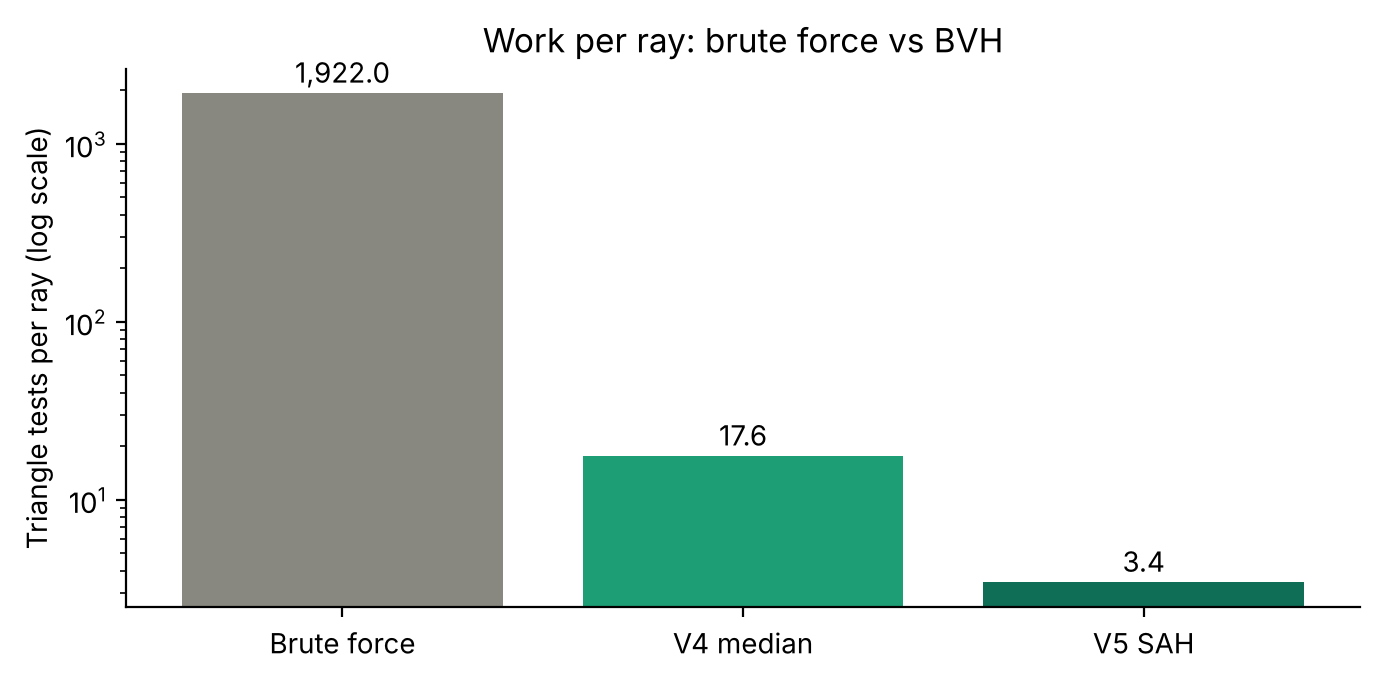

In [13]:
names = list(stats)
tri = [stats[k]["tri_tests"]/len(rays) for k in names]
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(names, tri, color=["#888780", "#1D9E75", "#0F6E56"])
ax.set_yscale("log"); ax.set_ylabel("Triangle tests per ray (log scale)")
ax.set_title("Work per ray: brute force vs BVH")
for b, v in zip(bars, tri): ax.text(b.get_x()+b.get_width()/2, v*1.15, f"{v:,.1f}", ha="center")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("work_per_ray.png", dpi=200); plt.show()

## 3. Scaling with N (random triangle soup)
Brute force grows linearly with N; the BVH grows roughly like log N.

250 {'Brute force': 250.0, 'V4 median': 9.3, 'V5 SAH': 4.6}
500 {'Brute force': 500.0, 'V4 median': 13.4, 'V5 SAH': 6.0}


1000 {'Brute force': 1000.0, 'V4 median': 16.6, 'V5 SAH': 9.3}


2000 {'Brute force': 2000.0, 'V4 median': 21.2, 'V5 SAH': 11.6}


4000 {'Brute force': 4000.0, 'V4 median': 24.0, 'V5 SAH': 14.1}


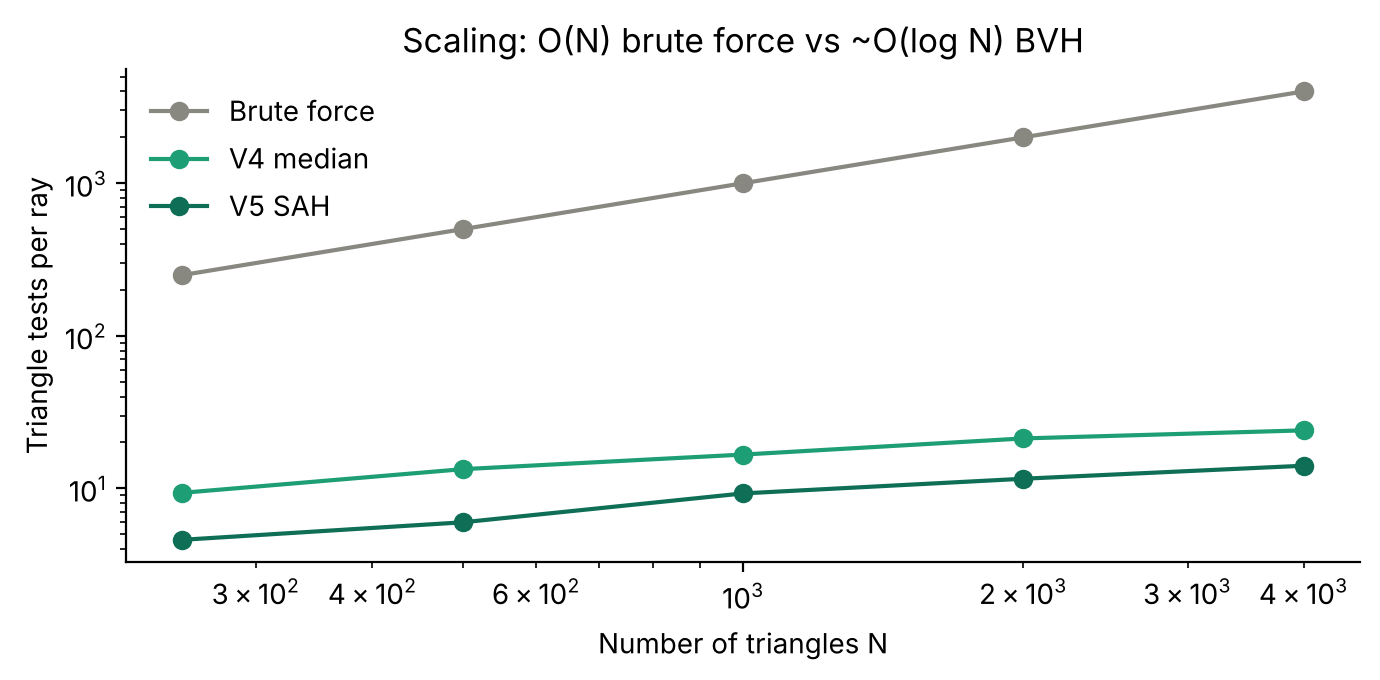

In [14]:
Ns = [250, 500, 1000, 2000, 4000]
res = {"Brute force": [], "V4 median": [], "V5 SAH": []}
for N in Ns:
    V, Fc = random_soup(N, seed=N)
    t4, t5 = v4_build(V, Fc), v5_build(V, Fc)
    r = random.Random(7); s = {k: new_stats() for k in res}
    for _ in range(200):
        o = (r.uniform(0, 10), r.uniform(0, 10), -2.0)
        d = normalize((r.uniform(-0.3, 0.3), r.uniform(-0.3, 0.3), 1.0))
        brute_force_closest_hit(o, d, V, Fc, s["Brute force"])
        v4_closest_hit(t4, o, d, s["V4 median"]); v5_closest_hit(t5, o, d, s["V5 SAH"])
    for k in res: res[k].append(s[k]["tri_tests"]/200)
    print(N, {k: round(v[-1], 1) for k, v in res.items()})

fig, ax = plt.subplots(figsize=(7, 3.5))
for k, c in zip(res, ["#888780", "#1D9E75", "#0F6E56"]): ax.plot(Ns, res[k], "o-", label=k, color=c)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Number of triangles N"); ax.set_ylabel("Triangle tests per ray")
ax.set_title("Scaling: O(N) brute force vs ~O(log N) BVH"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("scaling.png", dpi=200); plt.show()

## 4. Check the handwritten Q4 numbers

In [15]:
print("Unsplit leaf:", 10 * 2)
print("Median split:", sah_split_cost(100, 90, 5, 20, 5))
print("SAH split:   ", round(sah_split_cost(100, 50, 2, 10, 8), 2))
print("SAH vs median speed-up:", round(12 / 4.6, 2), "x")

Unsplit leaf: 20
Median split: 12.0
SAH split:    4.6
SAH vs median speed-up: 2.61 x


## 5. Render the scene with V5 (96 × 64 pixels)

Rendered 6144 rays in 0.06 s with V5


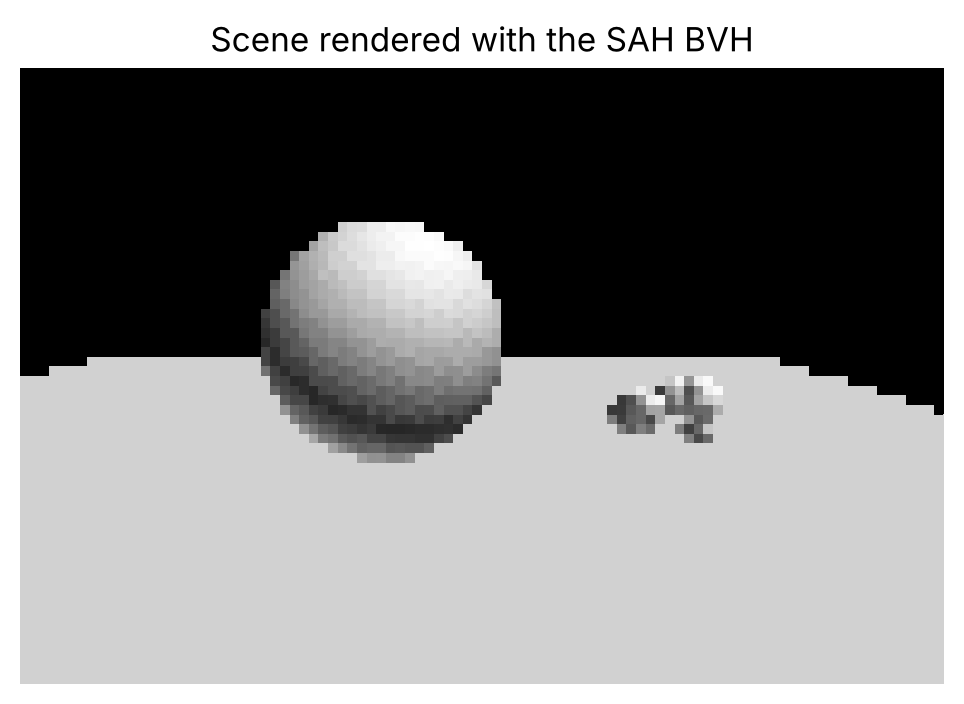

In [16]:
W, H = 96, 64
img = [[0.0]*W for _ in range(H)]
light = normalize((0.5, 1.0, 0.6))
t0 = time.perf_counter()
for px, py, o, d in camera_rays(W, H):
    tid, t = v5_closest_hit(bvh5, o, d)
    if tid is not None:
        n = triangle_normal(vertices, faces[tid])
        img[py][px] = 0.15 + 0.85 * abs(dot(n, light))
print(f"Rendered {W*H} rays in {time.perf_counter()-t0:.2f} s with V5")
plt.figure(figsize=(6, 4)); plt.imshow(img, cmap="gray", vmin=0, vmax=1); plt.axis("off")
plt.title("Scene rendered with the SAH BVH"); plt.savefig("render.png", dpi=200, bbox_inches="tight"); plt.show()